# Background aerosol, precursors and NOx: PD vs FUT

**Question.** What aerosol and ozone-precursor background do the PD and FUT runs see, and how different is it?

**How the background is set.** OsloAero aerosol is prognostic: the model computes it from emissions. What is *prescribed* is the emissions, plus the ocean DMS concentration and the SST. Each run repeats **one year** of every emission file (`CYCLICAL`):

| | PD (`NF2000…`, use case `2000_cam6_noresm_tropstratchem`) | FUT (`NF2100ssp585…`, use case `2100ssp585_cam6_noresm_tropstratchem`) |
|---|---|---|
| Anthropogenic, aircraft, biomass burning, tropospheric volcanic | CMIP6 historical (`cmip6_emissions_version20211124`, 1849–2015), **year 2000** | SSP5-8.5 REMIND-MAgPIE (`cmip6_emissions_version20230630`, 2014–2301), **year 2100** |
| Stratospheric volcanic | VolcanEESM v3.10 piControl, mean 1850–2014 (same file) | same file |
| Soil NOx/NH3, ocean CO/VOC ("other") | CMIP6 1750–2015, one year repeated | `emissions_ssp585_2deg`, one year repeated |
| Ocean DMS concentration | NorESM2 NHIST 1995–2005 climatology | NorESM2 SSP5-8.5 2090–2100 climatology |
| Sea salt, dust, MEGAN BVOC | online | online |
| Winds | nudged to PD met | same PD winds |

Biomass burning is **prescribed** in both periods (CMIP6 / SSP5-8.5 values), not interactive.

**What this notebook shows.**
1. The inputs, read from the resolved `CaseDocs/atm_in` of CTRL_PD `-20261029` and CTRL_FUT `-20261028` (new chain). The other runs of a period use the same use case.
2. Global emission totals of the year each run reads (2000 or 2100), by sector.
3. Maps PD, FUT, FUT − PD of the emissions.
4. Ocean DMS concentration (input).
5. What the model makes of it: AOD, sulfate burden, droplet number, surface SO₂, DMS, NOx, O₃, CO (CTRL_PD vs CTRL_FUT, 2001–2014).
6. Time series of the whole prescribed files, of which the runs read only one year.

**Units.** Emissions in the files are molecules cm⁻² s⁻¹ (surface) or molecules cm⁻³ s⁻¹ (vertical). They are converted with the molar mass the model uses (`chem_mech.doc`): BC and OM count as **C (12.011 g/mol)** and SO4_PR as **H₂SO₄**, so masses are what the model receives. Vertical files are integrated over the layer thickness (`altitude_int`). Annual totals are weighted by days per month (noleap).

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
import re
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

CASEDIR = Path.home() / 'cases/BRL_FRST_XPSN'
CASES = {'PD': 'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029',
         'FUT': 'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028'}
ALIAS = {'PD': 'CTRL_PD', 'FUT': 'CTRL_FUT'}
PROC = Path('../../data/processed-data/postprocessing')
PROC_YEARS = '2001-2014'
DMS_DIR = Path('/cluster/shared/noresm/inputdata/noresm-only/atm/cam/camoslo')
OUT = Path('background_aerosol_pd_fut_outputs')
CACHE, FIG, TAB = OUT / 'cache', OUT / 'figures', OUT / 'tables'  # cache = regenerable totals and maps
for d in (CACHE, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
N_WORKERS = 8

NA, R_EARTH = 6.02214076e23, 6.371e6
DPM = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])  # noleap
# project palette, in order; gold = total; PD = navy, FUT = red
TEAL, NAVY, PLUM, RED, ORANGE, GOLD, GREY = '#5D9A92', '#2C3990', '#9A4A84', '#BC423E', '#DE7A3A', '#EBC45C', '#CCCCCC'
PCOL = {'PD': NAVY, 'FUT': RED}

# molar mass (g/mol) of each species as the model counts it (chem_mech.doc formula)
MW = dict(SO2=64.066, SO4_PR=98.079, BC_AX=12.011, BC_N=12.011, BC_NI=12.011, OM_NI=12.011,
          NO=30.006, NO2=46.006, CO=28.010, NH3=17.031, DMS=62.134, ISOP=68.117, MTERP=136.234,
          BENZENE=78.112, BIGALK=72.149, BIGENE=56.106, C2H2=26.037, C2H4=28.053, C2H5OH=46.068,
          C2H6=30.069, C3H6=42.080, C3H8=44.096, CH2O=30.026, CH3CHO=44.053, CH3CN=41.052,
          CH3COCH3=58.079, CH3COCHO=72.063, CH3COOH=60.052, CH3OH=32.042, GLYALD=60.052,
          HCN=27.025, HCOOH=46.025, MEK=72.106, TOLUENE=92.138, XYLENES=106.165)
VOCS = [s for s in MW if s not in ('SO2', 'SO4_PR', 'BC_AX', 'BC_N', 'BC_NI', 'OM_NI', 'NO', 'NO2', 'CO', 'NH3', 'DMS')]
S, N = 32.06, 14.007
GROUPS = {  # group -> {species: factor to the group unit}
    'SOx (Tg S)': {'SO2': S / MW['SO2'], 'SO4_PR': S / MW['SO4_PR']},
    'BC (Tg C)': {'BC_AX': 1, 'BC_N': 1, 'BC_NI': 1},
    'OM (Tg)': {'OM_NI': 1},
    'NOx (Tg N)': {'NO': N / MW['NO'], 'NO2': N / MW['NO2']},
    'NH3 (Tg)': {'NH3': 1},
    'CO (Tg)': {'CO': 1},
    'NMVOC (Tg)': {s: 1 for s in VOCS},
}
SECTORS = ['anthropogenic, surface', 'anthropogenic, elevated', 'aircraft', 'biomass burning',
           'volcanic, tropospheric', 'volcanic, stratospheric', 'natural (soil / ocean)']
SCOL = dict(zip(SECTORS, [TEAL, NAVY, PLUM, RED, ORANGE, ORANGE, GREY]))

## 1. Inputs, from the resolved namelists

Each entry of `srf_emis_specifier` (surface) and `ext_frc_specifier` (3-D) is one file. A factor in front of the path (e.g. `0.9*`) scales it: the stratospheric volcanic SO₂ goes 90 % to SO2 and 10 % to SO4_PR. E90 is an idealised tracer and is skipped.

In [2]:
def sector(path):
    n = Path(path).name
    for key, lab in [('Volcan', 'volcanic, stratospheric'), ('_anthrosurf', 'anthropogenic, surface'),
                     ('_anthroprof', 'anthropogenic, elevated'), ('_air', 'aircraft'), ('_bb', 'biomass burning'),
                     ('_volc', 'volcanic, tropospheric'), ('_other_', 'natural (soil / ocean)')]:
        if key in n:
            return lab
    raise ValueError(n)

def read_inputs(period):
    txt = (CASEDIR / CASES[period] / 'CaseDocs/atm_in').read_text()
    cyc = {k: int(re.search(rf'{k}\s*=\s*(\d+)', txt).group(1)) for k in ('srf_emis_cycle_yr', 'ext_frc_cycle_yr')}
    assert len(set(cyc.values())) == 1, cyc
    for k in ('srf_emis_type', 'ext_frc_type'):
        assert re.search(rf"{k}\s*=\s*'CYCLICAL'", txt), k
    rows = []
    for key in ('srf_emis_specifier', 'ext_frc_specifier'):
        block = re.search(rf'{key}\s*=\s*(.*?)\n\s*\w+\s*=', txt, re.S).group(1)
        for item in re.findall(r"'([^']*)'", block):
            sp, rhs = [s.strip() for s in item.split('->')]
            if sp == 'E90':  # idealised tracer
                continue
            m = re.match(r'(?:([0-9.]+)\*)?(\S+)', rhs)
            rows.append(dict(period=period, species=sp, sector=sector(m.group(2)), scale=float(m.group(1) or 1),
                             namelist=key, path=m.group(2)))
    return pd.DataFrame(rows), cyc['srf_emis_cycle_yr']

INPUTS, CYCLE = [], {}
for p in CASES:
    df, CYCLE[p] = read_inputs(p)
    INPUTS.append(df)
INPUTS = pd.concat(INPUTS, ignore_index=True)
assert not INPUTS.duplicated(['period', 'species', 'sector']).any()
assert set(INPUTS.species) <= set(MW), set(INPUTS.species) - set(MW)
print('cycle year:', CYCLE)
print('files per period:', INPUTS.groupby('period').size().to_dict())
shared = set(INPUTS.query('period == "PD"').path) & set(INPUTS.query('period == "FUT"').path)
print('files used by both periods:', [Path(f).name for f in shared])
with pd.option_context('display.max_colwidth', 90, 'display.max_rows', 200):
    tab = INPUTS.assign(file=INPUTS.path.map(lambda f: Path(f).name)).pivot_table(
        index=['species', 'sector'], columns='period', values='file', aggfunc='first')[['PD', 'FUT']]
    tab.to_csv(TAB / 'input_files.csv')
    display(tab)

cycle year: {'PD': 2000, 'FUT': 2100}
files per period: {'FUT': 83, 'PD': 83}
files used by both periods: ['VolcanEESMv3.10_piControl_SO2_1850-2014average_date_2000_2100_2deg_ZeroTrop_c190701.nc']


period                                                                                                                   PD  \
species  sector                                                                                                               
BC_AX    aircraft                        emissions_cmip6_noresm2_BC_AX_airALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, elevated  emissions_cmip6_noresm2_BC_AX_anthroprofALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, surface    emissions_cmip6_noresm2_BC_AX_anthrosurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BC_N     aircraft                         emissions_cmip6_noresm2_BC_N_airALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, elevated   emissions_cmip6_noresm2_BC_N_anthroprofALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, surface     emissions_cmip6_noresm2_BC_N_anthrosurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BC_NI    biomass burning                  emissions_cmip6_noresm2_BC_NI_bbALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
BENZENE  anthropogenic, surface   emissions_cmip6_noresm2_BENZENE_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021...   
         biomass burning             emissions_cmip6_noresm2_BENZENE_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BIGALK   anthropogenic, surface   emissions_cmip6_noresm2_BIGALK_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version20211...   
         biomass burning              emissions_cmip6_noresm2_BIGALK_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BIGENE   anthropogenic, surface   emissions_cmip6_noresm2_BIGENE_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version20211...   
         biomass burning              emissions_cmip6_noresm2_BIGENE_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
C2H2     anthropogenic, surface   emissions_cmip6_noresm2_C2H2_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C2H2_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
C2H4     anthropogenic, surface   emissions_cmip6_noresm2_C2H4_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C2H4_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C2H4_other_surface_1750-2015_1.9x2.5_c20170322.nc   
C2H5OH   anthropogenic, surface   emissions_cmip6_noresm2_C2H5OH_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version20211...   
         biomass burning              emissions_cmip6_noresm2_C2H5OH_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
C2H6     anthropogenic, surface   emissions_cmip6_noresm2_C2H6_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C2H6_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C2H6_other_surface_1750-2015_1.9x2.5_c20170322.nc   
C3H6     anthropogenic, surface   emissions_cmip6_noresm2_C3H6_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C3H6_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C3H6_other_surface_1750-2015_1.9x2.5_c20170322.nc   
C3H8     anthropogenic, surface   emissions_cmip6_noresm2_C3H8_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C3H8_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C3H8_other_surface_1750-2015_1.9x2.5_c20170322.nc   
CH2O     anthropogenic, surface   emissions_cmip6_noresm2_CH2O_

## 2. Read every file once

For each file: the global total of every month in the file (→ annual totals, for the time series of §6) and the annual map of the cycle year (§3). The cycle year must have 12 months in the file. Years with fewer than 12 months (first/last of a file) are dropped from the totals. Results are cached in `cache/`; reading all files (~40 GB) takes several minutes.

In [3]:
def cell_area(lat, nlon):
    lat = np.asarray(lat, float)
    edges = np.clip(np.concatenate([[-90], 0.5 * (lat[1:] + lat[:-1]), [90]]), -90, 90)
    band = R_EARTH**2 * np.deg2rad(360 / nlon) * np.diff(np.sin(np.deg2rad(edges)))
    return np.repeat(band[:, None], nlon, axis=1)  # m2

def read_file(args):
    path, species, scale, cycle_year = args
    with netCDF4.Dataset(path) as d:
        date = np.asarray(d['date'][:]).astype(int)
        names = [v for v, x in d.variables.items() if {'time', 'lat', 'lon'} <= set(x.dimensions)]
        vertical = 'altitude_int' in d.dimensions
        dz = np.diff(np.asarray(d['altitude_int'][:], float)) * 1e5 if vertical else None  # km -> cm
        lat, lon = np.asarray(d['lat'][:], float), np.asarray(d['lon'][:], float)
        area = cell_area(lat, len(lon))
        conv = scale * 1e4 / NA * MW[species] * 1e-3  # molecules cm-2 s-1 -> kg m-2 s-1
        tot, cmap, ncyc = np.zeros(len(date)), np.zeros(area.shape), 0
        for i0 in range(0, len(date), 12):
            sl = slice(i0, min(i0 + 12, len(date)))
            col = 0.
            for v in names:
                x = np.nan_to_num(np.ma.filled(d[v][sl].astype('f8'), 0.))
                col = col + (np.tensordot(x, dz, axes=([1], [0])) if vertical else x)
            flux = col * conv
            tot[sl] = (flux * area).sum((1, 2))  # kg s-1
            for k, dt in enumerate(date[sl]):
                if dt // 10000 == cycle_year:
                    cmap += flux[k] * DPM[dt // 100 % 100 - 1] * 86400
                    ncyc += 1
    assert ncyc == 12, (path, ncyc)
    mon = date // 100 % 100
    g = pd.DataFrame(dict(year=date // 10000, kg=tot * DPM[mon - 1] * 86400)).groupby('year').kg.agg(['sum', 'size'])
    annual = g['sum'][g['size'] == 12] / 1e9  # Tg yr-1
    return dict(annual=annual, map=cmap, lat=lat, lon=lon, vertical=vertical, vars=','.join(names))

f_tot, f_map = CACHE / 'annual_totals.csv', CACHE / 'cycle_year_maps.nc'
if f_tot.is_file() and f_map.is_file() and not REBUILD_CACHE:
    TOT = pd.read_csv(f_tot)
    MAPS = xr.open_dataarray(f_map).load()
else:
    args = [(r.path, r.species, r.scale, CYCLE[r.period]) for r in INPUTS.itertuples()]
    with ProcessPoolExecutor(N_WORKERS) as ex:
        res = list(ex.map(read_file, args))
    TOT = pd.concat([pd.DataFrame(dict(period=r.period, species=r.species, sector=r.sector, year=o['annual'].index,
                                       Tg=o['annual'].values, vertical=o['vertical'], vars=o['vars']))
                     for r, o in zip(INPUTS.itertuples(), res)], ignore_index=True)
    lat0, lon0 = res[0]['lat'], res[0]['lon']
    assert all(np.allclose(o['lat'], lat0) and np.allclose(o['lon'], lon0) for o in res)
    MAPS = xr.DataArray(np.stack([o['map'] for o in res]), dims=('entry', 'lat', 'lon'),
                        coords=dict(lat=lat0, lon=lon0, **{c: ('entry', INPUTS[c].to_numpy(dtype=str))  # numpy str, not pandas StringDtype
                                                       for c in ('period', 'species', 'sector')}),
                        name='emission', attrs=dict(units='kg m-2 yr-1', note='cycle year, column-integrated'))
    TOT.to_csv(f_tot, index=False)
    MAPS.to_netcdf(f_map)
AREA = xr.DataArray(cell_area(MAPS.lat, MAPS.lon.size), dims=('lat', 'lon'), coords=dict(lat=MAPS.lat, lon=MAPS.lon))
assert abs(AREA.sum() / (4 * np.pi * R_EARTH**2) - 1) < 1e-6
# check: map of the cycle year integrates to the annual total
chk = (MAPS * AREA).sum(('lat', 'lon')).values / 1e9
tot_i = TOT.set_index(['period', 'species', 'sector', 'year']).Tg
ref = [tot_i[(r.period, r.species, r.sector, CYCLE[r.period])] for r in INPUTS.itertuples()]
assert np.allclose(chk, ref, rtol=1e-6)
print(TOT.groupby(['period', 'vertical']).species.nunique())

period  vertical
FUT     False       33
        True         8
PD      False       33
        True         8
Name: species, dtype: int64


## 3. Global totals of the year each run reads

PD = year 2000 of the PD files, FUT = year 2100 of the FUT files. Groups: SOx = SO2 + primary SO4 (Tg S); BC = BC_AX + BC_N + BC_NI; NOx = NO + NO2 (Tg N); NMVOC = sum of the prescribed VOC species (anthropogenic, biomass burning and ocean; MEGAN emissions are online and not included).

In [4]:
cyc = TOT[TOT.year == TOT.period.map(CYCLE)]
rows = []
for g, mem in GROUPS.items():
    sub = cyc[cyc.species.isin(list(mem))]
    val = (sub.Tg * sub.species.map(mem)).groupby([sub.period, sub.sector]).sum()
    for (p, s), v in val.items():
        rows.append(dict(group=g, period=p, sector=s, value=v))
BYSEC = pd.DataFrame(rows).pivot_table(index=['group', 'sector'], columns='period', values='value', fill_value=0)[['PD', 'FUT']]
TOTAL = BYSEC.groupby(level='group', sort=False).sum().loc[list(GROUPS)]
for t in (BYSEC, TOTAL):
    t['FUT − PD'] = t.FUT - t.PD
    t['FUT / PD'] = t.FUT / t.PD.where(t.PD != 0)
TOTAL.to_csv(TAB / 'emission_totals_cycle_year.csv')
BYSEC.to_csv(TAB / 'emission_totals_cycle_year_by_sector.csv')
with pd.option_context('display.float_format', '{:.3g}'.format):
    display(TOTAL)
    display(BYSEC)

period,PD,FUT,FUT − PD,FUT / PD
group,,,,
SOx (Tg S),70.6,29.7,-40.9,0.421
BC (Tg C),7.47,3.32,-4.15,0.444
OM (Tg),55.4,42.1,-13.3,0.76
NOx (Tg N),48.4,37.4,-11,0.773
NH3 (Tg),57,84.2,27.2,1.48
CO (Tg),908,598,-310,0.658
NMVOC (Tg),197,164,-33.1,0.832


period                                  PD     FUT  FUT − PD  FUT / PD
group      sector                                                     
BC (Tg C)  aircraft                0.00899  0.0231    0.0141      2.57
           anthropogenic, elevated    1.24   0.479    -0.759     0.387
           anthropogenic, surface     4.57    1.16     -3.41     0.254
           biomass burning            1.65    1.66   0.00466         1
CO (Tg)    aircraft                  0.528   0.578    0.0493      1.09
           anthropogenic, surface      599     239      -360     0.399
           biomass burning             289     338      49.4      1.17
           natural (soil / ocean)     19.9    19.9         0         1
NH3 (Tg)   anthropogenic, surface     51.2    77.6      26.3      1.51
           biomass burning            3.41    4.24     0.831      1.24
           natural (soil / ocean)     2.35    2.35         0         1
NMVOC (Tg) anthropogenic, surface      138    99.2     -39.2     0.717
           biomass burning            53.6    59.7      6.11      1.11
           natural (soil / ocean)     5.19    5.19         0         1
NOx (Tg N) aircraft                  0.801    3.13      2.33      3.91
           anthropogenic, surface     36.4    22.5     -13.9     0.618
           biomass burning            6.28    6.89     0.606       1.1
           natural (soil / ocean)     4.95    4.95         0         1
OM (Tg)    aircraft                0.00621 0.00737   0.00116      1.19
           anthropogenic, elevated    2.89    1.26     -1.63     0.436
           anthropogenic, surface     17.6    3.15     -14.4     0.179
           biomass burning            34.9    37.7      2.76      1.08
SOx (Tg S) aircraft                   0.12   0.142    0.0224      1.19
           anthropogenic, elevated    44.6    11.6       -33      0.26
           anthropogenic, surface     9.92    2.03     -7.89     0.205
           biomass burning            1.01       1  -0.00817     0.992
           volcanic, stratospheric   0.296   0.296         0         1
           volcanic, tropospheric     14.6    14.6         0         1

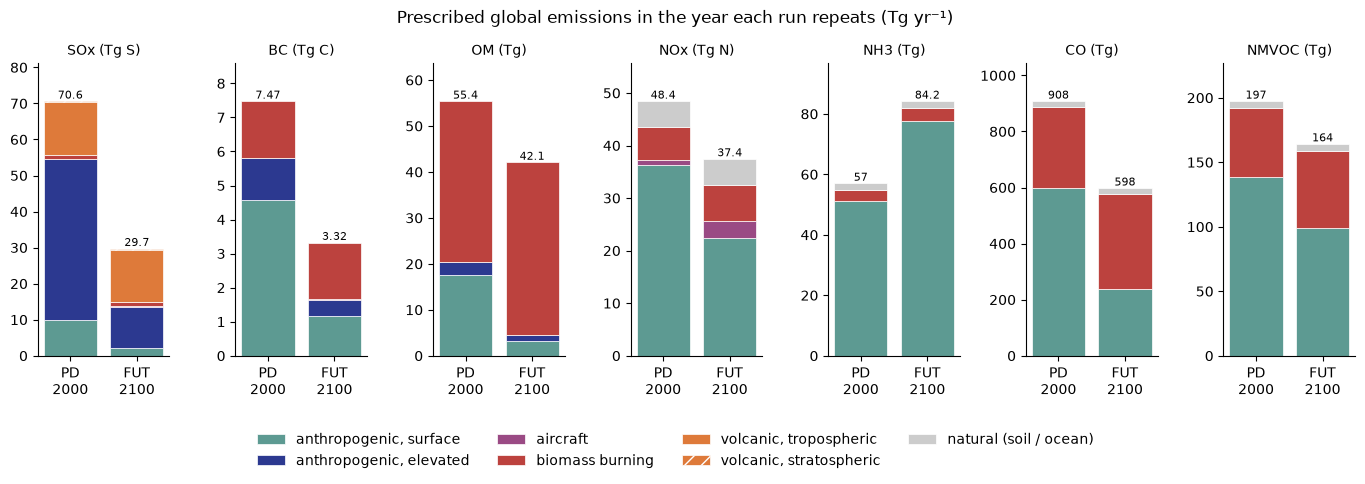

In [5]:
fig, axs = plt.subplots(1, len(GROUPS), figsize=(17, 3.8), gridspec_kw=dict(wspace=0.5))
for ax, g in zip(axs, GROUPS):
    sub = BYSEC.loc[g]
    bottom = np.zeros(2)
    for s in SECTORS:
        if s in sub.index:
            v = sub.loc[s, ['PD', 'FUT']].values
            ax.bar([0, 1], v, bottom=bottom, color=SCOL[s], edgecolor='white', lw=0.5,
                   hatch='//' if s == 'volcanic, stratospheric' else None, label=s)
            bottom += v
    for x, v in enumerate(bottom):
        ax.text(x, v, f'{v:.3g}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks([0, 1], [f'PD\n{CYCLE["PD"]}', f'FUT\n{CYCLE["FUT"]}'])
    ax.set_title(g, fontsize=10)
    ax.set_ylim(0, bottom.max() * 1.15)
    ax.spines[['top', 'right']].set_visible(False)
h, l = [], []
for ax in axs:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l:
            h.append(hh); l.append(ll)
fig.legend(h, l, loc='upper center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Prescribed global emissions in the year each run repeats (Tg yr⁻¹)', y=1.02)
fig.savefig(FIG / 'emission_totals_cycle_year.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Emission maps: PD, FUT, FUT − PD

Column-integrated, all sectors, g m⁻² yr⁻¹ (SOx in g S, NOx in g N). Absolute maps on a log scale; the difference on a symmetric log-spaced scale (RdBu_r, red = more in FUT). Cells below the lowest level are white.

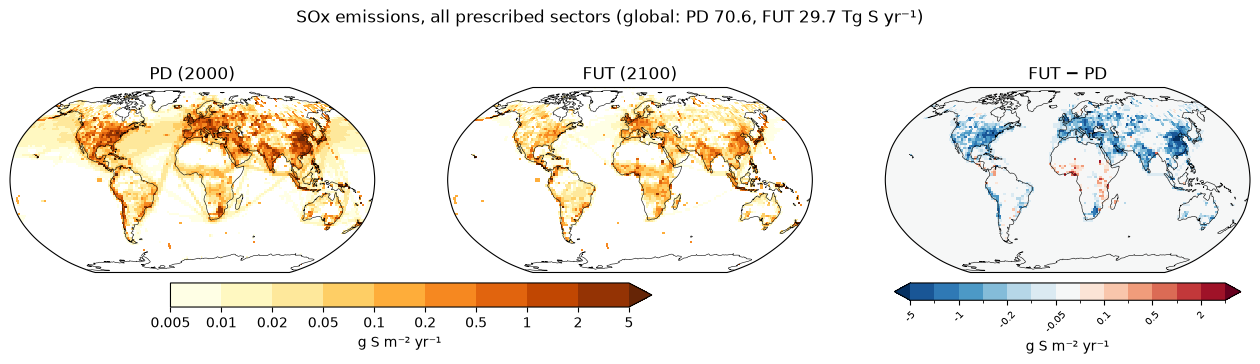

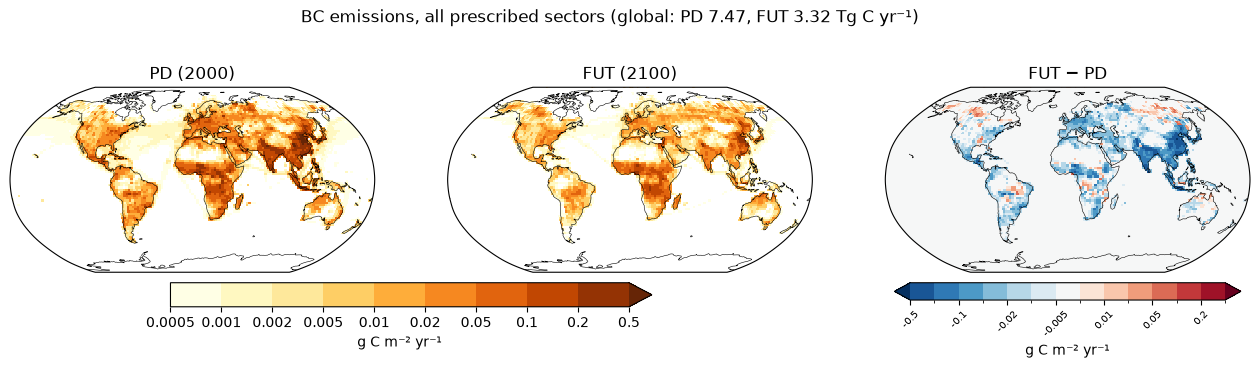

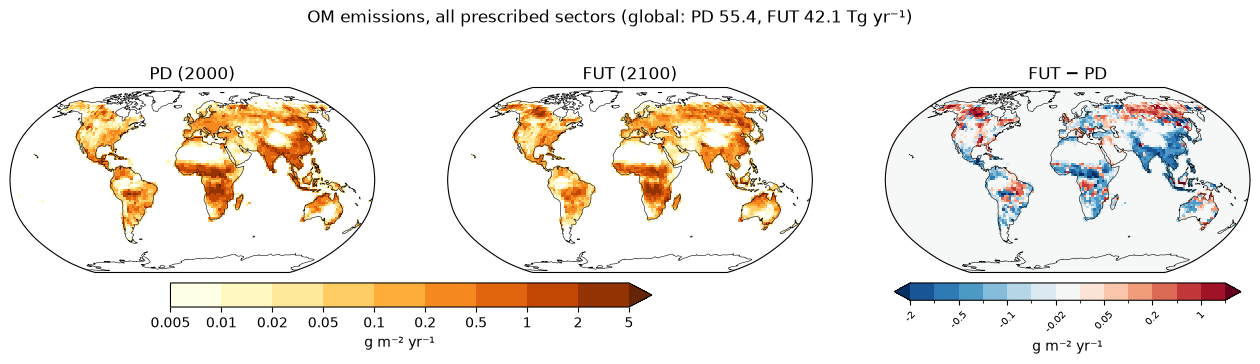

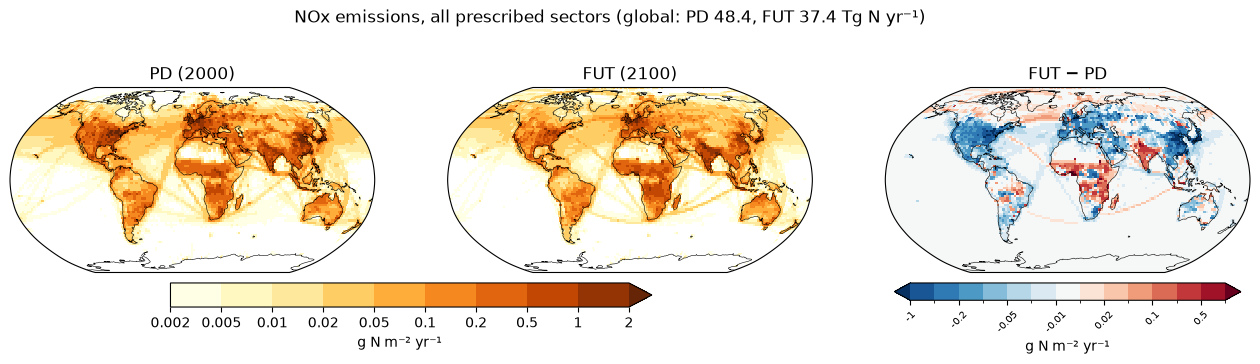

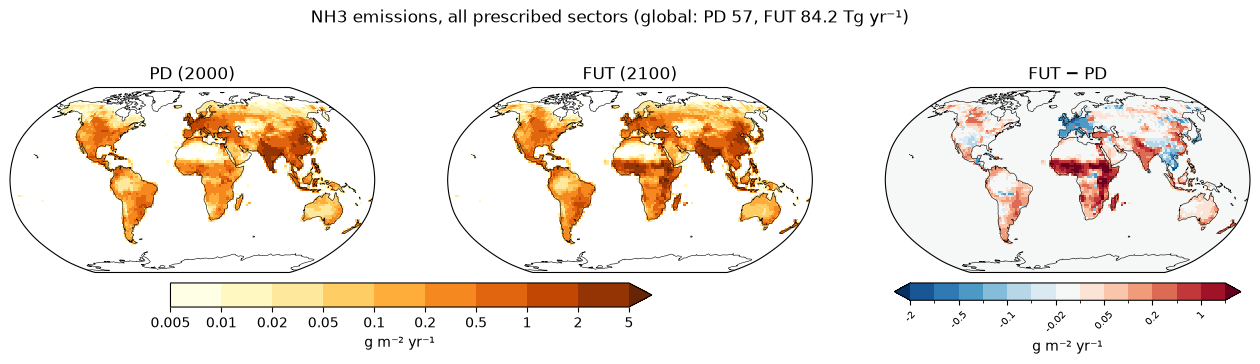

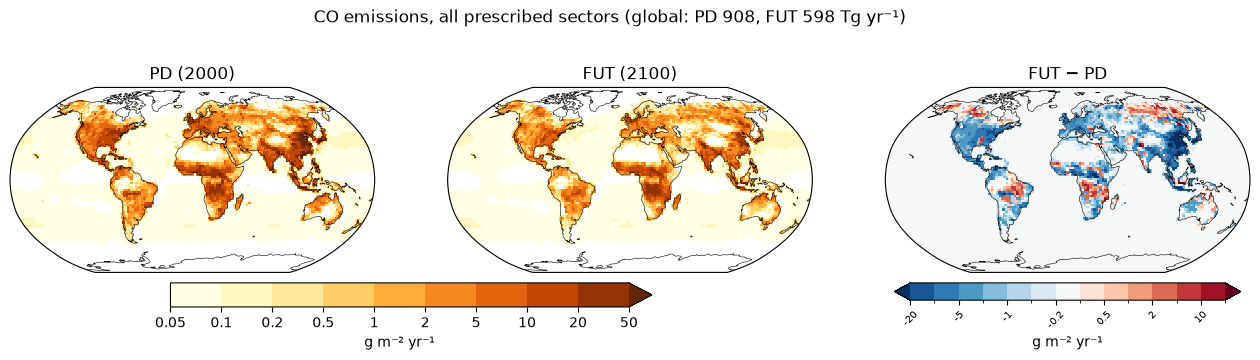

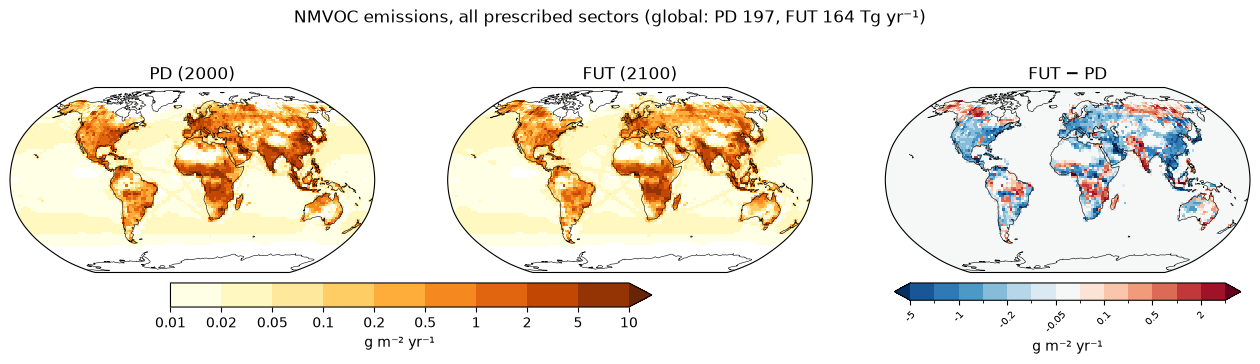

In [6]:
def group_map(period, g):
    mem = GROUPS[g]
    sel = MAPS.where((MAPS.period == period) & MAPS.species.isin(list(mem)), drop=True)
    w = xr.DataArray([mem[s] for s in sel.species.values], dims='entry')
    return (sel * w).sum('entry') * 1e3  # g m-2 yr-1

def nice_levels(vmax, decades=3):
    """1-2-5 levels from the first one >= vmax down by `decades` decades."""
    e = np.floor(np.log10(vmax))
    cand = np.array([m * 10.0**k for k in np.arange(e - decades - 1, e + 2) for m in (1, 2, 5)])
    hi = cand[cand >= vmax * 0.999][0]
    return cand[(cand <= hi) & (cand >= hi / 10**decades * 0.999)]

def cyclic(da):
    return xr.concat([da, da.isel(lon=0).assign_coords(lon=360.)], 'lon')

def draw(ax, da, cmap, norm):
    da = cyclic(da)
    im = ax.pcolormesh(da.lon, da.lat, da, cmap=cmap, norm=norm, transform=ccrs.PlateCarree(), shading='nearest')
    ax.coastlines(lw=0.4)
    return im

def triptych(fields, title, unit, fname, decades=3):
    """fields = {'PD': da, 'FUT': da}; log-scale absolute, symmetric log-spaced difference."""
    pd_, fu = fields['PD'], fields['FUT']
    diff = fu - pd_
    vmax = float(np.nanpercentile(np.r_[pd_.values.ravel(), fu.values.ravel()], 99.5))
    lv = nice_levels(vmax, decades)
    cm_abs = plt.get_cmap('YlOrBr').copy()
    cm_abs.set_under('white')
    norm_abs = mcolors.BoundaryNorm(lv, cm_abs.N, extend='max')
    dmax = float(np.nanpercentile(abs(diff.values), 99.5))
    dl = nice_levels(dmax, decades - 1)
    dlev = np.r_[-dl[::-1], dl]  # the central bin (-dl[0], dl[0]) is white
    cm_d = plt.get_cmap('RdBu_r')
    norm_d = mcolors.BoundaryNorm(dlev, cm_d.N, extend='both')
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.4), subplot_kw=dict(projection=ccrs.Robinson()))
    for ax, (lab, da) in zip(axs[:2], [(f'PD ({CYCLE["PD"]})', pd_), (f'FUT ({CYCLE["FUT"]})', fu)]):
        im = draw(ax, da, cm_abs, norm_abs)
        ax.set_title(lab)
    fig.colorbar(im, ax=axs[:2], orientation='horizontal', shrink=0.6, pad=0.04, ticks=lv, label=unit,
                 format=lambda x, _: f'{x:g}')
    im = draw(axs[2], diff, cm_d, norm_d)
    axs[2].set_title('FUT − PD')
    cb = fig.colorbar(im, ax=axs[2], orientation='horizontal', shrink=0.95, pad=0.04, ticks=dlev[::2] if len(dlev) > 12 else dlev,
                      label=unit, format=lambda x, _: f'{x:g}')
    cb.ax.tick_params(labelsize=7, rotation=45)
    fig.suptitle(title, y=1.03)
    fig.savefig(FIG / fname, dpi=200, bbox_inches='tight')
    plt.show()

for g in GROUPS:
    short = g.split()[0]
    unit = 'g ' + g.split('(Tg')[1].strip(' )') + ' m⁻² yr⁻¹' if '(Tg ' in g else 'g m⁻² yr⁻¹'
    triptych({p: group_map(p, g) for p in CASES}, f'{short} emissions, all prescribed sectors '
             f'(global: PD {TOTAL.loc[g, "PD"]:.3g}, FUT {TOTAL.loc[g, "FUT"]:.3g} {g.split("(")[1].strip(")")} yr⁻¹)',
             unit, f'emission_map_{short}.png')

Biomass burning alone (part of every map above), because it is prescribed in both periods and it is the sector closest to the boreal region of the paper.

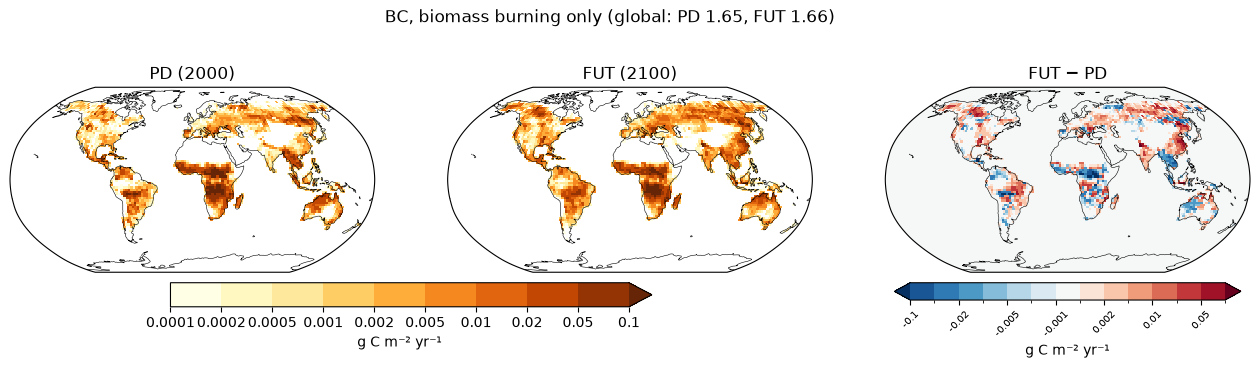

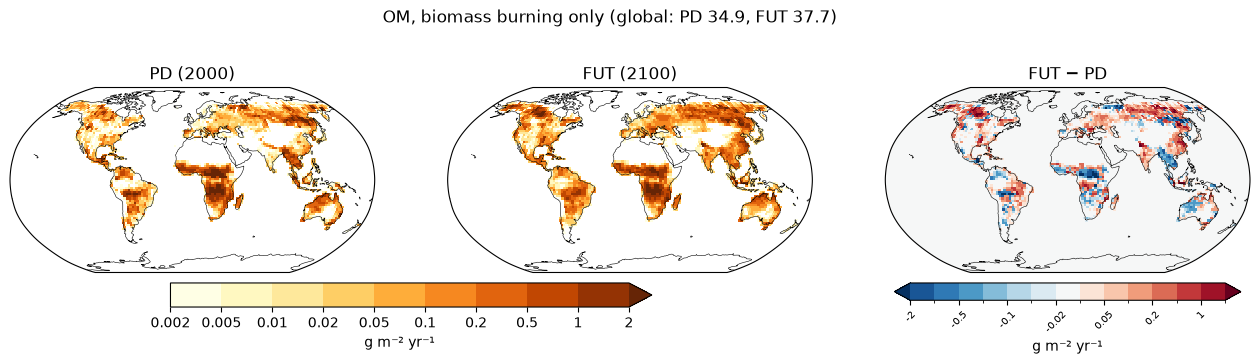

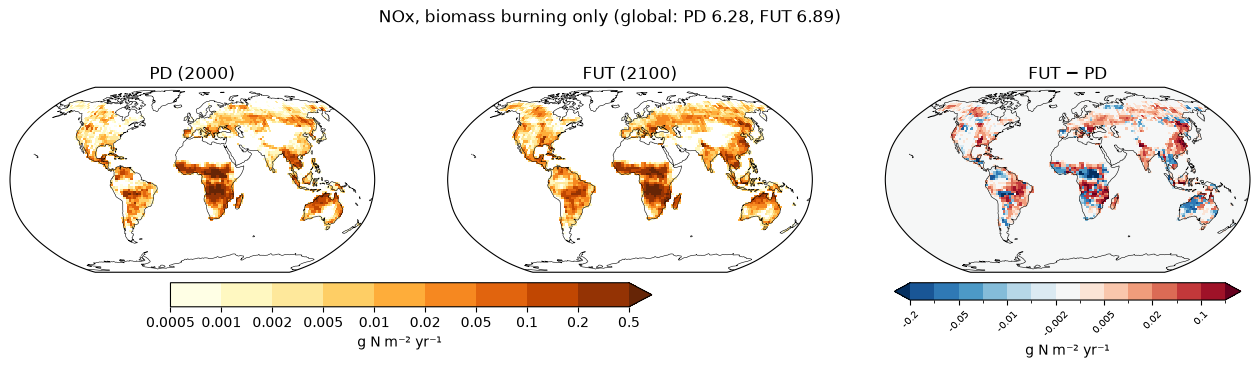

In [7]:
def sector_map(period, g, sec):
    mem = GROUPS[g]
    sel = MAPS.where((MAPS.period == period) & MAPS.species.isin(list(mem)) & (MAPS.sector == sec), drop=True)
    w = xr.DataArray([mem[s] for s in sel.species.values], dims='entry')
    return (sel * w).sum('entry') * 1e3

for g in ['BC (Tg C)', 'OM (Tg)', 'NOx (Tg N)']:
    short = g.split()[0]
    unit = 'g ' + g.split('(Tg')[1].strip(' )') + ' m⁻² yr⁻¹' if '(Tg ' in g else 'g m⁻² yr⁻¹'
    b = BYSEC.loc[(g, 'biomass burning')]
    triptych({p: sector_map(p, g, 'biomass burning') for p in CASES},
             f'{short}, biomass burning only (global: PD {b.PD:.3g}, FUT {b.FUT:.3g})', unit, f'emission_map_{short}_biomass_burning.png')

## 5. Ocean DMS concentration (input)

The DMS flux is computed online from this seawater concentration and the wind speed, so the flux itself is not prescribed (and `SFDMS` is not in the output). Annual mean, weighted by days per month.

PD dms-hamocc-dow-taylor_chlor_a-lanaclim_NHIST_f19_tn14_20190710_1995-2005_cycle_version20260209.nc
FUT dms-hamocc-dow-taylor_chlor_a-lanaclim_NSSP585frc2_f19_tn14_20191014_2090-2100_cycle_version20260209.nc
ocean-area mean DMS (nmol/L): {'PD': 2.04, 'FUT': 1.903} FUT/PD = 0.933


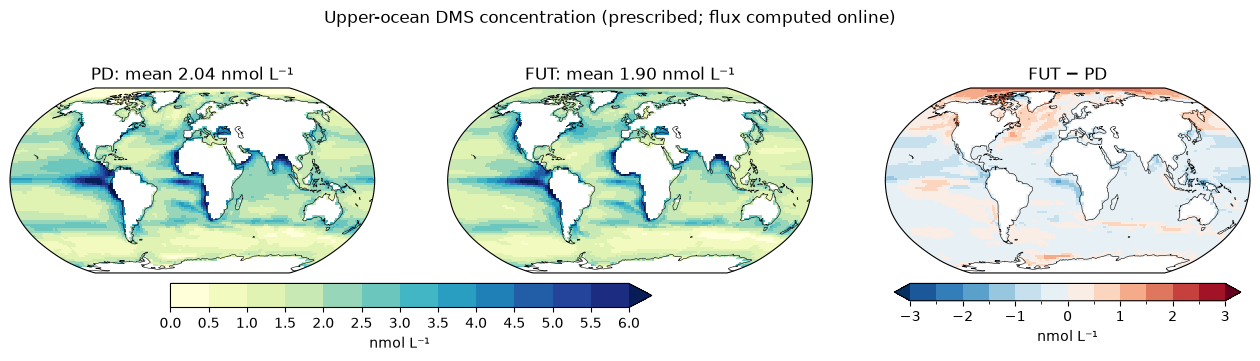

In [8]:
def nml(period, key):
    txt = (CASEDIR / CASES[period] / 'CaseDocs/atm_in').read_text()
    return re.search(rf"{key}\s*=\s*'?([^'\n]+?)'?\s*\n", txt).group(1).strip()

DMS = {}
for p in CASES:
    f = DMS_DIR / nml(p, 'ocean_filename')
    print(p, f.name)
    with xr.open_dataset(f, decode_times=False) as ds:
        assert ds.sizes['time'] == 12
        assert np.allclose(ds.lat, MAPS.lat) and np.allclose(ds.lon, MAPS.lon)
        ann = (ds.dms.fillna(0) * xr.DataArray(DPM, dims='time')).sum('time') / DPM.sum()
        DMS[p] = ann.where(ann > 0).assign_coords(lat=MAPS.lat, lon=MAPS.lon)  # land = 0 -> NaN
ocean = DMS['PD'].notnull() & DMS['FUT'].notnull()
mean = {p: float((DMS[p] * AREA).where(ocean).sum() / AREA.where(ocean).sum()) for p in CASES}
print('ocean-area mean DMS (nmol/L):', {p: round(v, 3) for p, v in mean.items()}, f'FUT/PD = {mean["FUT"] / mean["PD"]:.3f}')

fig, axs = plt.subplots(1, 3, figsize=(16, 3.4), subplot_kw=dict(projection=ccrs.Robinson()))
lv = np.arange(0, 6.5, 0.5)
norm = mcolors.BoundaryNorm(lv, plt.get_cmap('YlGnBu').N, extend='max')
for ax, p in zip(axs[:2], CASES):
    im = draw(ax, DMS[p], 'YlGnBu', norm)
    ax.set_title(f'{p}: mean {mean[p]:.2f} nmol L⁻¹')
fig.colorbar(im, ax=axs[:2], orientation='horizontal', shrink=0.6, pad=0.04, ticks=lv, label='nmol L⁻¹')
dl = np.arange(-3, 3.5, 0.5)
im = draw(axs[2], DMS['FUT'] - DMS['PD'], 'RdBu_r', mcolors.BoundaryNorm(dl, plt.get_cmap('RdBu_r').N, extend='both'))
axs[2].set_title('FUT − PD')
fig.colorbar(im, ax=axs[2], orientation='horizontal', shrink=0.95, pad=0.04, ticks=dl[::2], label='nmol L⁻¹')
fig.suptitle('Upper-ocean DMS concentration (prescribed; flux computed online)', y=1.03)
fig.savefig(FIG / 'ocean_dms_concentration.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. What the model makes of it: CTRL_PD vs CTRL_FUT, 2001–2014

Processed monthly files (first 12 months already dropped), means weighted by days per month. Surface = lowest model level. These are model results, so they include the online sources (sea salt, dust, DMS, MEGAN) and the FUT climate (SST, CO₂), not only the prescribed emissions. Both runs are nudged to the same PD winds.

In [9]:
MODEL_VARS = {  # name: (category, variable(s), surface?, factor, unit)
    'AOD 550 nm': ('AEROPT', ['DOD550'], False, 1, '1'),
    'absorption AOD 550 nm': ('AEROPT', ['ABS550'], False, 1, '1'),
    'sulfate burden': ('SULFATE', ['cb_SULFATE'], False, 1e6, 'mg m⁻²'),
    'droplet column': ('CLOUDPROP', ['CDNUMC'], False, 1e-10, '10¹⁰ m⁻²'),
    'surface SO₂': ('SULFATE', ['SO2'], True, 1e12, 'ppt'),
    'surface DMS': ('SULFATE', ['DMS'], True, 1e12, 'ppt'),
    'surface NOx': ('CHEM', ['NO', 'NO2'], True, 1e12, 'ppt'),
    'surface O₃': ('CHEM', ['O3'], True, 1e9, 'ppb'),
    'surface CO': ('CHEM', ['CO'], True, 1e9, 'ppb'),
    'O₃ column': ('CHEM', ['cb_O3'], False, 1e3, 'g m⁻²'),
}

def load_model(period):
    out, files = {}, {}
    for name, (cat, vs, sfc, fac, unit) in MODEL_VARS.items():
        f = PROC / f'{ALIAS[period]}_atm_{cat}_{PROC_YEARS}.nc'
        if f not in files:
            files[f] = xr.open_dataset(f)
        ds = files[f]
        assert ds.attrs['casename'] == CASES[period], (f, ds.attrs['casename'])
        assert ds.time.encoding.get('calendar') == 'noleap'
        da = sum(ds[v].isel(lev=-1) if sfc else ds[v] for v in vs)
        days = (ds.time_bnds[:, 1] - ds.time_bnds[:, 0]).dt.days
        out[name] = ((da * days).sum('time') / days.sum()).load() * fac
    assert all(float(ds.lev[-1]) > 900 for ds in files.values() if 'lev' in ds.dims)
    return out

MODEL = {p: load_model(p) for p in CASES}
for p in CASES:
    for k in MODEL[p]:
        assert np.allclose(MODEL[p][k].lat, MAPS.lat) and np.allclose(MODEL[p][k].lon, MAPS.lon)
        MODEL[p][k] = MODEL[p][k].assign_coords(lat=MAPS.lat, lon=MAPS.lon)

LAT = AREA.lat.broadcast_like(AREA)
REGIONS = {'global': AREA, 'NH': AREA * (LAT > 0), 'SH': AREA * (LAT < 0), '46–82°N': AREA * ((LAT >= 46) & (LAT <= 82)),
           'Arctic >66.5°N': AREA * (LAT > 66.5)}
rows = []
for name, (_, _, _, _, unit) in MODEL_VARS.items():
    for r, w in REGIONS.items():
        v = {p: float((MODEL[p][name] * w).sum() / w.sum()) for p in CASES}
        rows.append(dict(variable=name, unit=unit, region=r, PD=v['PD'], FUT=v['FUT'], **{'FUT − PD': v['FUT'] - v['PD'],
                         'change %': 100 * (v['FUT'] / v['PD'] - 1)}))
MODEL_TAB = pd.DataFrame(rows).set_index(['variable', 'unit', 'region'])
MODEL_TAB.to_csv(TAB / 'model_levels_ctrl_pd_fut_2001-2014.csv')
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.max_rows', 100):
    display(MODEL_TAB.xs('global', level='region'))
    display(MODEL_TAB.xs('46–82°N', level='region'))

,,PD,FUT,FUT − PD,change %
variable,unit,,,,
AOD 550 nm,1,0.202,0.215,0.0124,6.14
absorption AOD 550 nm,1,0.00482,0.00438,-0.000443,-9.19
sulfate burden,mg m⁻²,6.23,3.78,-2.45,-39.3
droplet column,10¹⁰ m⁻²,1.16,1.05,-0.106,-9.21
surface SO₂,ppt,297,96.9,-200,-67.4
surface DMS,ppt,96.3,130,34,35.3
surface NOx,ppt,641,410,-231,-36
surface O₃,ppb,28,28.9,0.903,3.23
surface CO,ppb,79.6,103,23.8,29.9


,,PD,FUT,FUT − PD,change %
variable,unit,,,,
AOD 550 nm,1,0.134,0.112,-0.0212,-15.9
absorption AOD 550 nm,1,0.00339,0.00255,-0.000835,-24.6
sulfate burden,mg m⁻²,8.9,4.79,-4.11,-46.2
droplet column,10¹⁰ m⁻²,1.83,1.58,-0.246,-13.4
surface SO₂,ppt,530,83.1,-447,-84.3
surface DMS,ppt,49.4,136,87,176
surface NOx,ppt,1.07e+03,541,-529,-49.4
surface O₃,ppb,39.8,39.5,-0.298,-0.749
surface CO,ppb,98.2,106,7.82,7.97


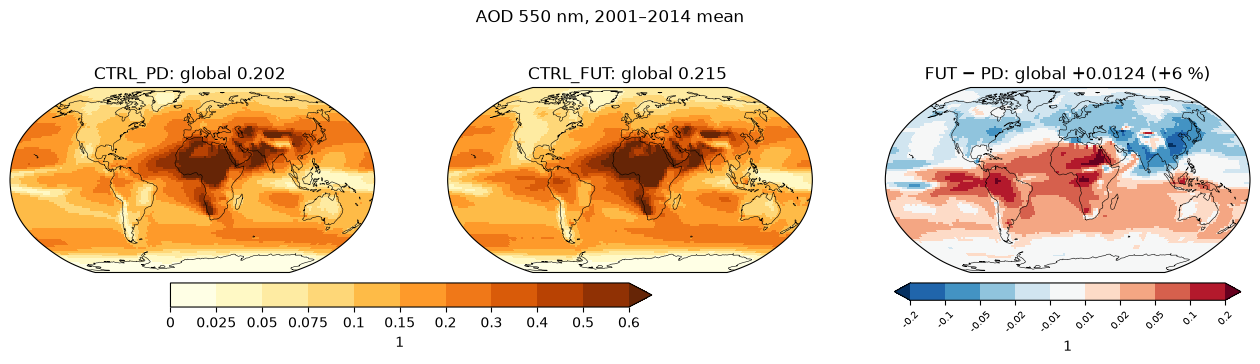

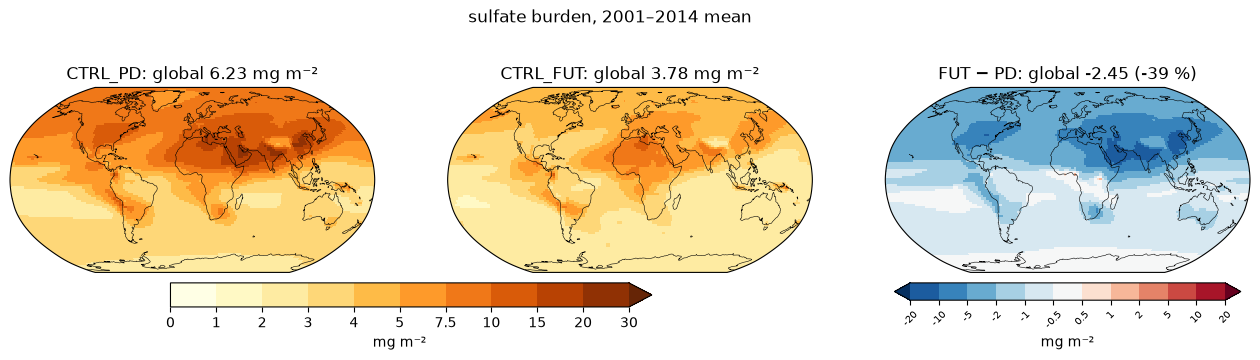

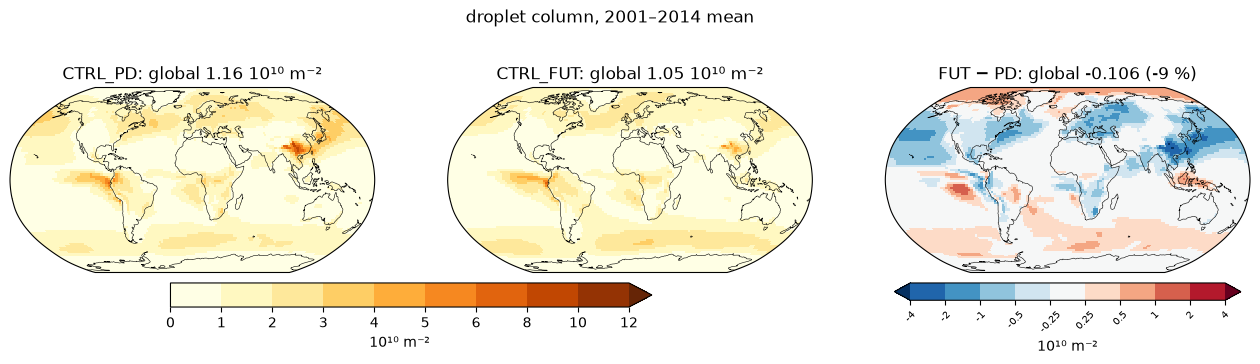

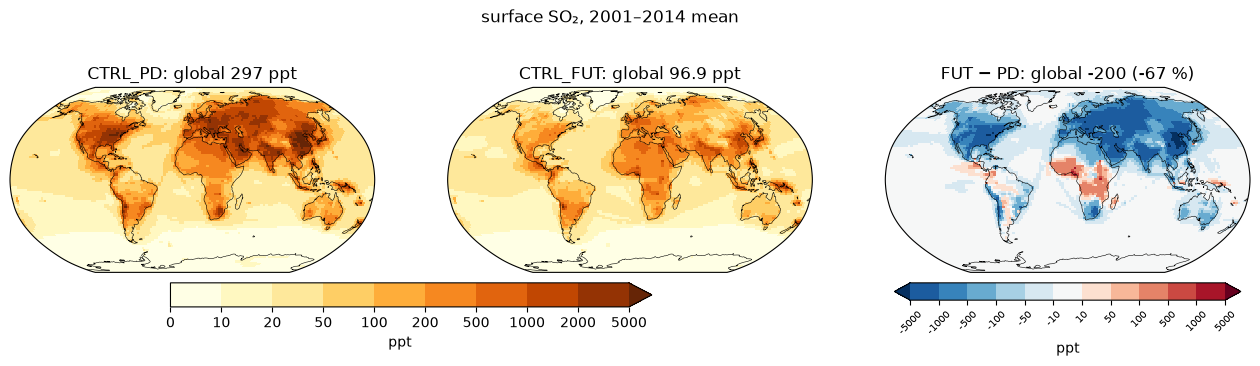

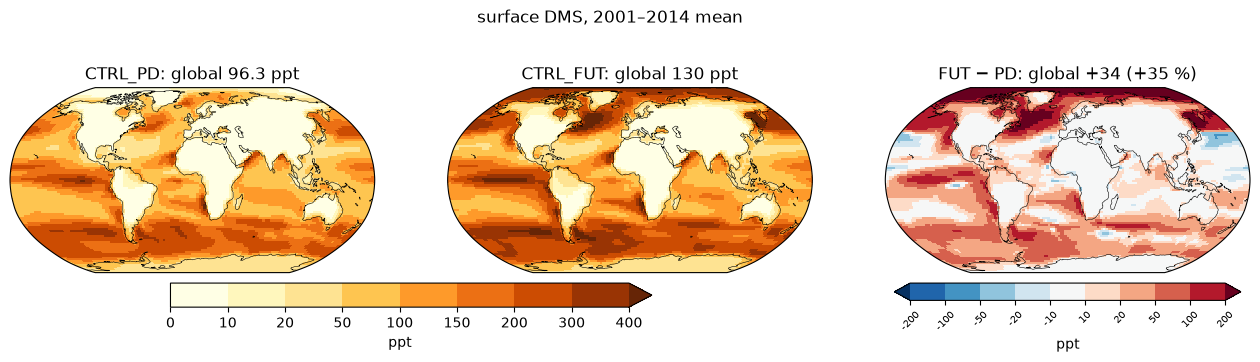

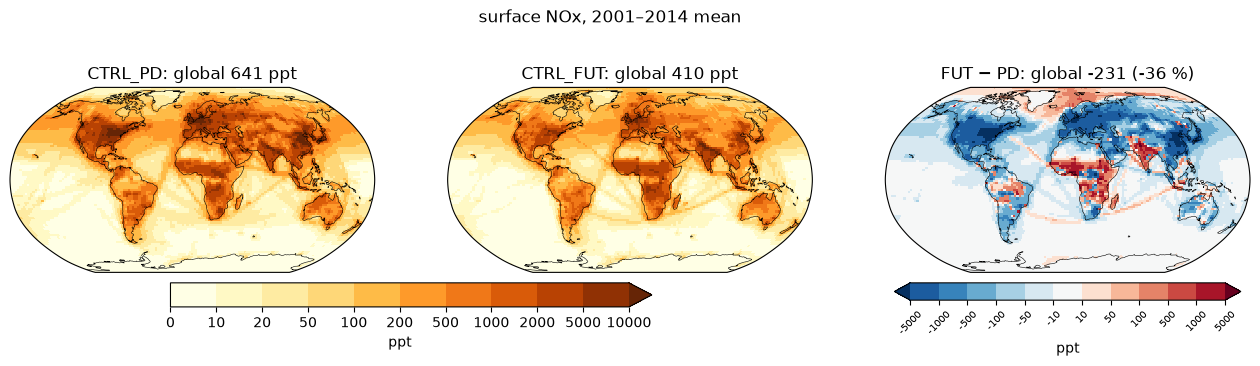

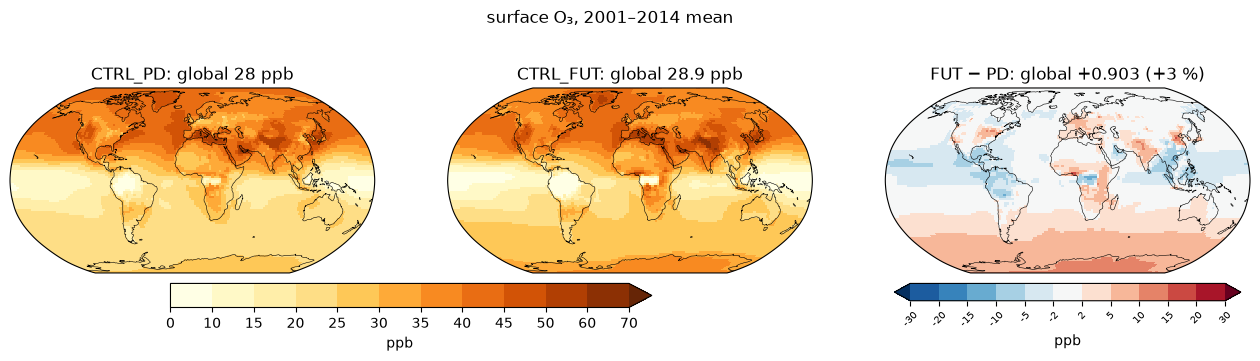

In [10]:
def triptych_lin(name, levels, dlevels, cmap='YlOrBr'):
    unit = MODEL_VARS[name][4]
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.4), subplot_kw=dict(projection=ccrs.Robinson()))
    norm = mcolors.BoundaryNorm(levels, plt.get_cmap(cmap).N, extend='max')
    g = MODEL_TAB.loc[(name, unit, 'global')]
    for ax, p in zip(axs[:2], CASES):
        im = draw(ax, MODEL[p][name], cmap, norm)
        ax.set_title(f'{ALIAS[p]}: global {g[p]:.3g} {unit if unit != "1" else ""}')
    fig.colorbar(im, ax=axs[:2], orientation='horizontal', shrink=0.6, pad=0.04, ticks=levels, label=unit, format=lambda x, _: f'{x:g}')
    im = draw(axs[2], MODEL['FUT'][name] - MODEL['PD'][name], 'RdBu_r', mcolors.BoundaryNorm(dlevels, plt.get_cmap('RdBu_r').N, extend='both'))
    axs[2].set_title(f'FUT − PD: global {g["FUT − PD"]:+.3g} ({g["change %"]:+.0f} %)')
    cb = fig.colorbar(im, ax=axs[2], orientation='horizontal', shrink=0.95, pad=0.04, ticks=dlevels, label=unit, format=lambda x, _: f'{x:g}')
    cb.ax.tick_params(labelsize=7, rotation=45)
    fig.suptitle(f'{name}, 2001–2014 mean', y=1.03)
    fig.savefig(FIG / f'model_map_{re.sub(r"[^A-Za-z0-9]+", "_", name.replace("₂", "2").replace("₃", "3")).strip("_")}.png', dpi=200, bbox_inches='tight')
    plt.show()

sym = lambda *v: np.r_[-np.array(v[::-1]), np.array(v)]
triptych_lin('AOD 550 nm', [0, .025, .05, .075, .1, .15, .2, .3, .4, .5, .6], sym(.01, .02, .05, .1, .2))
triptych_lin('sulfate burden', [0, 1, 2, 3, 4, 5, 7.5, 10, 15, 20, 30], sym(.5, 1, 2, 5, 10, 20))
triptych_lin('droplet column', [0, 1, 2, 3, 4, 5, 6, 8, 10, 12], sym(.25, .5, 1, 2, 4))
triptych_lin('surface SO₂', [0, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000], sym(10, 50, 100, 500, 1000, 5000))
triptych_lin('surface DMS', [0, 10, 20, 50, 100, 150, 200, 300, 400], sym(10, 20, 50, 100, 200))
triptych_lin('surface NOx', [0, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000], sym(10, 50, 100, 500, 1000, 5000))
triptych_lin('surface O₃', [0, 10, 15, 20, 25, 30, 35, 40, 45, 50, 60, 70], sym(2, 5, 10, 15, 20, 30))

## 7. Time series of the prescribed files (only one year is read)

Global annual totals of every file, by sector. **Solid** = PD files (CMIP6 historical, annual 1850–2014); **dashed with dots** = FUT files (SSP5-8.5; the files hold 2014, 2015, then every 10 years, plus 2301, not shown). The runs read only the year marked: **navy dot = PD (2000)**, **red dot = FUT (2100)**. Gold = sum of sectors. Stratospheric volcanic SO₂ is one 1850–2014 mean (same in both periods), drawn flat. The "natural" files repeat one year.

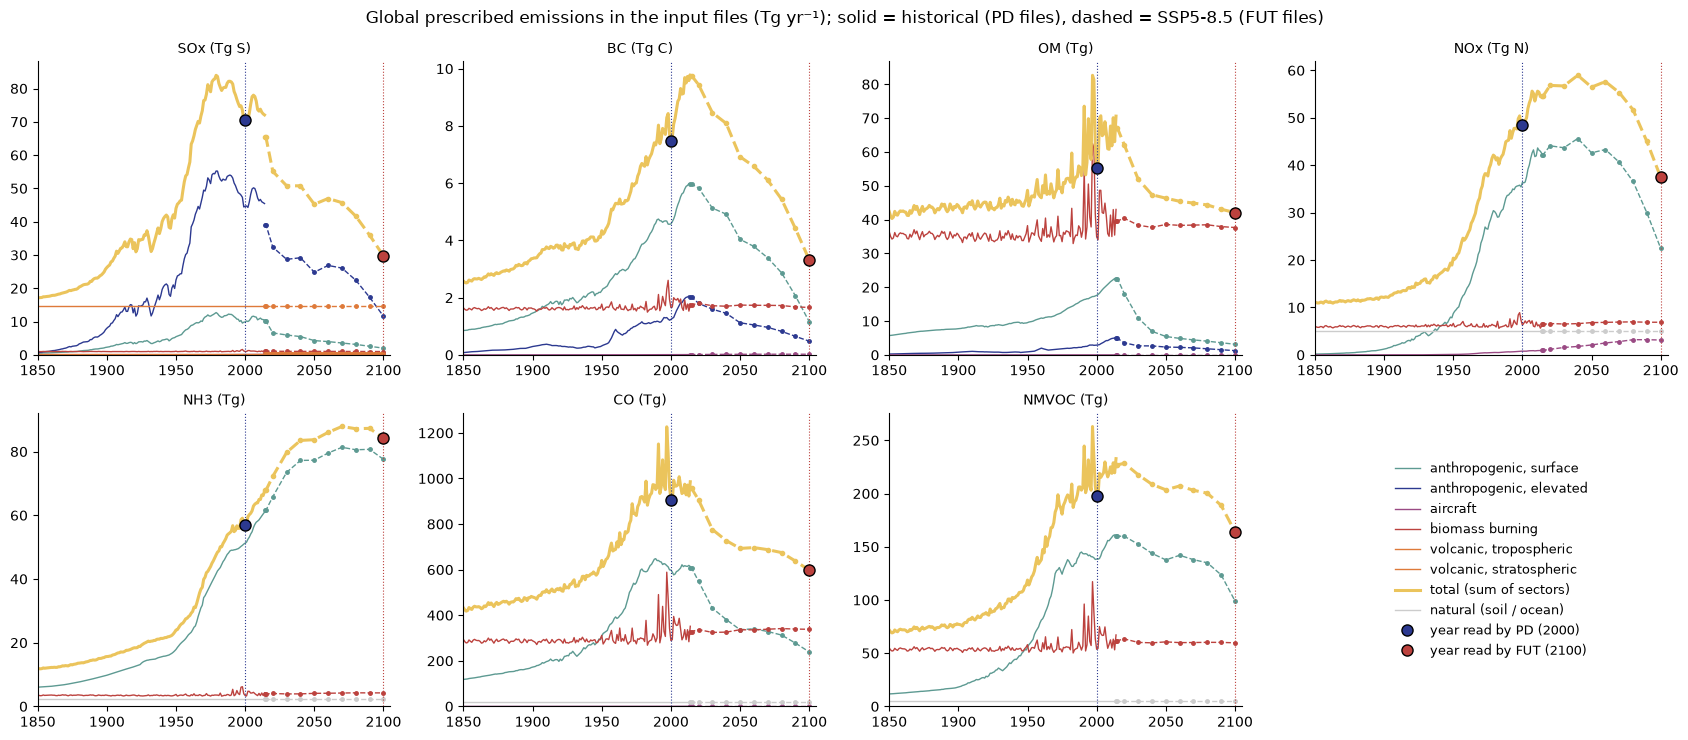

In [11]:
def group_series(period, g):
    mem = GROUPS[g]
    sub = TOT[(TOT.period == period) & TOT.species.isin(list(mem))]
    s = (sub.Tg * sub.species.map(mem)).groupby([sub.sector, sub.year]).sum().unstack('sector')
    span = (1850, 2014) if period == 'PD' else (2014, 2100)
    s = s.reindex(range(span[0], span[1] + 1))
    if 'volcanic, stratospheric' in s:  # one climatological year repeated
        s['volcanic, stratospheric'] = s['volcanic, stratospheric'].dropna().iloc[0]
    s = s.dropna(how='all')
    s['total'] = s.sum(axis=1, min_count=s.shape[1])  # only years with every sector
    return s

SERIES = {(p, g): group_series(p, g) for p in CASES for g in GROUPS}
pd.concat({f'{p}|{g}': s for (p, g), s in SERIES.items()}, names=['period|group']).to_csv(TAB / 'prescribed_file_timeseries_by_sector.csv')

fig, axs = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, g in zip(axs.flat, GROUPS):
    for p, ls, mk in [('PD', '-', None), ('FUT', '--', 'o')]:
        s = SERIES[p, g]
        for sec in [c for c in SECTORS if c in s]:
            d = s[sec].dropna()
            ax.plot(d.index, d.values, ls=ls, marker=mk, ms=2.5, lw=1, color=SCOL[sec],
                    label=sec if p == 'PD' or sec not in SERIES['PD', g] else None)
        d = s.total.dropna()
        ax.plot(d.index, d.values, ls=ls, marker=mk, ms=3, lw=2.2, color=GOLD, label='total (sum of sectors)' if p == 'PD' else None)
        y = CYCLE[p]
        ax.plot(y, s.total.get(y, np.nan), 'o', ms=8, mfc=PCOL[p], mec='k', zorder=5)
        ax.axvline(y, color=PCOL[p], lw=0.8, ls=':')
    ax.set_title(g, fontsize=10)
    ax.set_xlim(1850, 2105)
    ax.set_xticks(range(1850, 2101, 50))
    ax.set_ylim(bottom=0)
    ax.spines[['top', 'right']].set_visible(False)
h, l = [], []
for ax in axs.flat[:len(GROUPS)]:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l:
            h.append(hh); l.append(ll)
h += [plt.Line2D([], [], marker='o', ls='', mfc=PCOL[p], mec='k', ms=8) for p in CASES]
l += [f'year read by PD ({CYCLE["PD"]})', f'year read by FUT ({CYCLE["FUT"]})']
axs.flat[-1].axis('off')
axs.flat[-1].legend(h, l, loc='center', frameon=False, fontsize=9)
fig.suptitle('Global prescribed emissions in the input files (Tg yr⁻¹); solid = historical (PD files), dashed = SSP5-8.5 (FUT files)')
fig.tight_layout()
fig.savefig(FIG / 'prescribed_file_timeseries.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Summary

Tags: **(a)** read from the tables above · **(b)** inference.

**Prescribed emissions, year read (PD 2000 → FUT 2100, global)** (a)

| | PD | FUT | FUT/PD | what changes |
|---|---|---|---|---|
| SOx (Tg S) | 70.6 | 29.7 | 0.42 | anthropogenic −80 % (54.5 → 13.6); tropospheric volcanic 14.6 and stratospheric 0.30 unchanged → **half of FUT SOx is volcanic** |
| BC (Tg C) | 7.47 | 3.32 | 0.44 | anthropogenic −72 %; biomass burning unchanged (1.65) |
| OM (Tg) | 55.4 | 42.1 | 0.76 | anthropogenic −79 %; biomass burning +8 % (34.9 → 37.7), 90 % of FUT OM |
| NOx (Tg N) | 48.4 | 37.4 | 0.77 | anthropogenic surface −38 %; aircraft ×3.9 (0.8 → 3.1); soil NOx identical |
| NH3 (Tg) | 57.0 | 84.2 | 1.48 | the only species that rises (agriculture) |
| CO (Tg) | 908 | 598 | 0.66 | anthropogenic −60 %, biomass burning +17 % |
| NMVOC (Tg) | 197 | 164 | 0.83 | anthropogenic −28 %, biomass burning +11 % |

- **Biomass burning is prescribed in both periods and changes by at most ±20 %**, so FUT is not a more fire-prone world in this setup. (a)
- PD reads one single year (2000), not a climatology. Biomass burning in the historical files varies a lot from year to year in 1997–2014 (GFED era, §7), so the PD fire emissions belong to that one year. (a)
- The ocean DMS concentration is 7 % lower in FUT (ocean mean 2.04 → 1.90 nmol L⁻¹). (a)

**What the model makes of it (CTRL_PD → CTRL_FUT, 2001–2014)** (a)

| | global | 46–82°N |
|---|---|---|
| sulfate burden | 6.23 → 3.78 mg m⁻² (−39 %) | −46 % |
| surface SO₂ | −67 % | −84 % |
| surface NOx | −36 % | −49 % |
| surface O₃ | +3 % (28.0 → 28.9 ppb) | −1 % |
| surface CO | +30 % | +8 % |
| surface DMS | +35 % | **+176 %** |
| droplet column | −9 % | −13 % |
| AOD 550 nm | **+6 %** (0.202 → 0.215) | −16 % |
| absorption AOD | −9 % | −25 % |

Inferences (b):
- Global AOD goes **up** although sulfate falls by 39 %. The increase sits over the Sahara/Arabia and the tropical oceans, which points to more dust and sea salt (and water uptake) in the warmer FUT climate. This is not verified: the output has no AOD per component (the `A550_*` fields are absorption).
- Surface DMS rises although seawater DMS falls. Likely causes: less sea ice (more open ocean in the Arctic, hence +176 % at 46–82°N) and slower oxidation with less NOx. Not checked.
- CO rises although CO emissions fall: probably the much higher CH₄ of SSP5-8.5 in 2100 (CH₄ oxidation makes CO). Not checked here.
- Ozone barely changes: lower NOx and higher CH₄/CO roughly cancel.

**For the paper:** FUT is a **clean-air background** for anthropogenic aerosol (sulfate, BC, anthropogenic OM, NOx), with unchanged fires and volcanoes. BVOC-driven SOA formation and aerosol–cloud effects of the forest expansion therefore act on a lower sulfate/CCN background in FUT. (b)
